# Uplift — Tahap 2: observational pada panel Dunnhumby

Tahap sebelumnya membuktikan mesin uplift bekerja saat penugasan diacak. Di panel Dunnhumby kemewahan itu tidak ada: retailer yang memilih siapa yang ditarget, dan investigasi campaign effect sudah menunjukkan pola seleksi *win-back* — member dipilih justru saat belanjanya sedang turun, lalu sebagian pemulihannya terjadi secara alami. Pertanyaan tahap ini lebih sulit dan lebih bernilai: **bukan sekadar "berapa efek rata-rata" (sudah dijawab framework DiD), tapi member mana yang paling berubah** — sehingga voucher bisa dialokasikan ke decile atas.

Semua angka di bagian ini bersifat **observational — valid di bawah asumsi unconfoundedness**, bukan hasil eksperimen. Propensity, overlap weighting, dan placebo test mengurangi risiko bias; tidak menghapusnya. Keputusan desain yang mengikat dicatat di decision log.

## Desain: unit household × campaign, fitur hanya pra-campaign

Satu baris = satu (member, campaign terestimasi) dari 20 campaign yang diestimasi framework DiD — total 37.976 baris, 6.778 di antaranya treated. Definisi treated/control persis fase sebelumnya: control adalah member yang tidak ditarget campaign itu **dan** tidak ditarget campaign lain yang window-nya beririsan, sehingga estimasi tidak bias ke nol karena kontaminasi.

Fitur sembilan kolom, semuanya dihitung ketat **sebelum minggu mulai campaign** masing-masing: tujuh fitur pra-campaign yang sama dengan DiD (level belanja mingguan, minggu aktif, ketergantungan promo, ragam kategori, recency, tren paruh-akhir pra-campaign, level dip) ditambah tiga fitur riwayat — jumlah campaign sebelumnya, tingkat redemption sebelumnya (distink per campaign, bukan per kupon), dan lama jadi member. Outcome = perubahan belanja net mingguan Δ (rata-rata window campaign dikurangi rata-rata 8 minggu pra-campaign), satuan USD/minggu, konsisten dengan estimasi DiD.

Dua keputusan protektif: model hanya di-*fit* pada campaign train yang lolos gate reliabilitas (identifikasi bersih), dan evaluasi berjalan pada campaign akhir yang tidak pernah dilihat model — termasuk tiga campaign berflag, yang tetap tampil dengan flag-nya. Bobot evaluasi = overlap weights dari propensity per campaign, warisan desain DiD. Split mengikuti waktu: 12 campaign pertama (s.d. minggu mulai 77) untuk train, 8 campaign akhir (mulai minggu 81) untuk test; validasi silang di sisi train memakai `GroupKFold` per household karena member yang sama muncul di banyak campaign.

In [1]:
import sys
import time
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.uplift_eval import ate_bootstrap, auuc_summary, uplift_curve
from src.uplift_obs import (
    UPFIT_FEATURES, build_uplift_panel, campaign_time_split, evaluate_scores,
    feature_matrix, fit_final_models, group_cv_scores, load_stage2_inputs,
    placebo_permutation, save_stage2_outputs,
)

pd.set_option("display.width", 140)

inputs = load_stage2_inputs()
panel = build_uplift_panel(inputs)
split = campaign_time_split(panel)
train, test = split["train"], split["test"]
print(f"panel: {len(panel):,} baris | campaign terestimasi: {panel['campaign_id'].nunique()} | treated: {panel['treated'].sum():,} ({panel['treated'].mean():.1%})")
print(f"batas waktu: train s.d. minggu mulai {split['boundary']['train_max_start_week']}, test mulai minggu {split['boundary']['test_min_start_week']}")
meta = split["campaign_meta"]
meta["peran"] = np.where(meta["campaign_id"].isin(train["campaign_id"].unique()), "train", "test")
meta[["campaign_id", "start_week", "peran", "reliability_flag"]]

panel: 37,976 baris | campaign terestimasi: 20 | treated: 6,778 (17.8%)
batas waktu: train s.d. minggu mulai 77, test mulai minggu 81


,campaign_id,start_week,peran,reliability_flag
0,26,33,train,tidak reliable — pre-trend jauh
1,29,41,train,layak (observasional)
2,30,47,train,layak (observasional)
3,5,55,train,layak (observasional)
4,7,58,train,tidak reliable — pre-trend jauh
5,8,60,train,layak — utama (observasional)
6,9,63,train,layak (observasional)
7,10,67,train,tidak reliable — pre-trend jauh
8,11,69,train,layak (observasional)
9,12,69,train,layak (observasional)


In [2]:
panel[UPFIT_FEATURES].describe().round(2)

,spend_weekly_pre,active_weeks_pre,promo_share_mean_pre,breadth_mean_pre,recency_pre_end,spend_trend_pre,spend_dip_level,n_campaigns_before,redemption_rate_before,tenure_weeks
count,37976.00,37976.00,37976.00,37976.00,37976.00,37976.00,37976.00,37976.00,37976.00,37976.00
mean,23.82,3.74,0.16,6.27,4.35,0.43,23.21,0.89,0.03,58.92
std,33.89,2.69,0.14,7.49,10.00,22.39,35.17,1.74,0.13,19.19
min,-10.00,0.00,0.00,0.00,0.00,-252.65,-10.96,0.00,0.00,-64.00
25%,2.47,1.00,0.07,0.75,0.00,-6.95,0.00,0.00,0.00,46.00
50%,11.61,4.00,0.14,3.50,1.00,0.00,9.61,0.00,0.00,60.00
75%,31.55,6.00,0.22,9.12,3.00,7.49,31.10,1.00,0.00,75.00
max,579.03,8.00,2.99,54.00,89.00,291.47,628.75,16.00,1.00,94.00


Evaluasi membandingkan tiga cara mengurutkan member: **T-learner**, **X-learner** (propensity dimodelkan logistic — bukan konstan seperti tahap randomized — karena di sini assignment bergantung karakteristik member), dan **RFM naif** (urutkan menurut belanja pra-campaign: beri voucher ke yang belanjanya paling besar). Baseline keempat adalah *targeting acak*: garis lurus menuju efek rata-rata. Baseline naif bukan lawan main yang mudah — kalau model uplift kalah dari "beri saja ke yang belanja banyak", itu temuan yang jujur dan harus ditulis begitu.

In [3]:
fit_rows = train["reliability_flag"].str.startswith("layak")
d = train[fit_rows].reset_index(drop=True)
vocab = sorted(int(c) for c in d["campaign_id"].unique())
X_oof = feature_matrix(d, campaign_vocab=vocab)
t0 = time.time()
oof = group_cv_scores(X_oof, d["delta"].to_numpy(float), d["treated"].to_numpy(int), d["household_key"].to_numpy())
print(f"OOF GroupKFold(5) by household: {time.time()-t0:.0f}s | n fit = {len(d):,} baris / {len(vocab)} campaign lolos gate")

y_o, w_o, sw_o = d["delta"].to_numpy(float), d["treated"].to_numpy(int), d["att_weight"].to_numpy(float)
oof_rows = []
for name, s in [("T-learner (OOF train)", oof["score_t"]), ("X-learner (OOF train)", oof["score_x"])]:
    a = auuc_summary(y_o, w_o, s, sample_weight=sw_o)
    oof_rows.append({"skor": name, "AUUC": round(a["auuc"], 0), "random": round(a["auuc_random"], 0),
                     "skill": round(a["skill"], 0), "skill per member ($/mgg)": round(a["skill_per_client"], 3)})
pd.DataFrame(oof_rows)

D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


OOF GroupKFold(5) by household: 22s | n fit = 17,733 baris / 9 campaign lolos gate


,skor,AUUC,random,skill,skill per member ($/mgg)
0,T-learner (OOF train),28283.0,28545.0,-263.0,-0.015
1,X-learner (OOF train),29297.0,28545.0,752.0,0.042


In [4]:
models = fit_final_models(train)
X_test = feature_matrix(test, campaign_vocab=models["campaign_vocab"])
scores = {
    "T": models["t"].predict(X_test),
    "X": models["x"].predict(X_test),
    "RFM (spend pre)": test["spend_weekly_pre"].to_numpy(float),
}
t0 = time.time()
ev = evaluate_scores(test, scores, n_boot=1000)
print(f"evaluasi test (bootstrap 1.000): {time.time()-t0:.0f}s")

base = ev["baseline_random"]
print(f"targeting acak (ATE overlap-weighted): {base['ate']:+.2f} USD/mgg (95% CI {base['ci_low']:+.2f} s.d. {base['ci_high']:+.2f}, n={base['n']:,})")
rows = []
for name, s in ev["by_model"].items():
    frac, gain = uplift_curve(test["delta"].to_numpy(float), test["treated"].to_numpy(int), scores[name], sample_weight=test["att_weight"].to_numpy(float))
    i20 = np.searchsorted(frac, 0.2)
    rows.append({
        "skor": name,
        "AUUC": round(s["auuc"], 0),
        "skill": round(s["skill"], 0),
        "skill per member ($/mgg)": round(s["skill_per_client"], 3),
        "gain @20% per member ($/mgg)": round(gain[i20] / (0.2 * len(test)), 2),
    })
pd.DataFrame(rows)

D:\AnalyticsSpace\retail-voucher-incrementality\notebooks\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


evaluasi test (bootstrap 1.000): 4s
targeting acak (ATE overlap-weighted): +6.31 USD/mgg (95% CI +4.80 s.d. +7.68, n=14,090)


,skor,AUUC,skill,skill per member ($/mgg),gain @20% per member ($/mgg)
0,T,45773.0,1350.0,0.096,9.55
1,X,53244.0,8820.0,0.626,11.32
2,RFM (spend pre),49642.0,5219.0,0.370,8.08


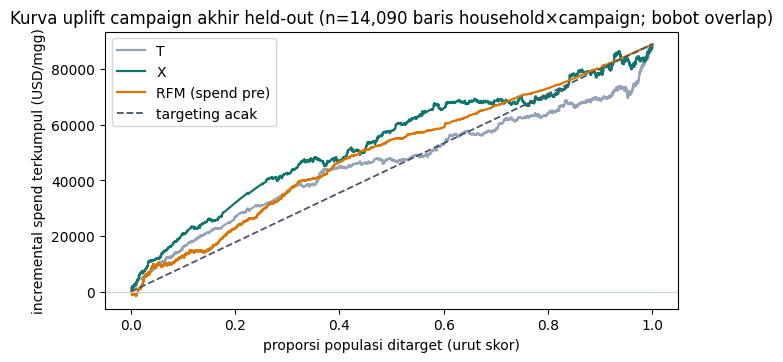

In [5]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
for name, color in [("T", "#94a3b8"), ("X", "#0f766e"), ("RFM (spend pre)", "#d97706")]:
    frac, gain = uplift_curve(test["delta"].to_numpy(float), test["treated"].to_numpy(int), scores[name], sample_weight=test["att_weight"].to_numpy(float))
    ax.plot(frac, gain, lw=1.6, color=color, label=name)
ax.plot([0, 1], [0, base["ate"] * len(test)], color="#475569", lw=1.3, ls="--", label="targeting acak")
ax.axhline(0, color="#cbd5e1", lw=0.8)
ax.set_xlabel("proporsi populasi ditarget (urut skor)")
ax.set_ylabel("incremental spend terkumpul (USD/mgg)")
ax.set_title(f"Kurva uplift campaign akhir held-out (n={len(test):,} baris household×campaign; bobot overlap)")
ax.legend()
plt.show()

In [6]:
for name in ("X", "RFM (spend pre)", "T"):
    dec = ev["deciles"][name]
    print(f"decile — {name}:")
    print(dec.round(2).to_string(index=False))
    print()

decile — X:
 decile    n  n_treated  n_control  uplift  ci_low  ci_high
      1 1409        296       1113   14.66    9.66    20.22
      2 1409        116       1293    4.40   -0.62     9.48
      3 1409         64       1345    2.58   -3.83     9.02
      4 1409        160       1249    3.49   -0.67     7.79
      5 1409        165       1244    7.45    3.19    12.13
      6 1409        168       1241    5.78    1.97    10.10
      7 1409        188       1221    1.88   -1.86     5.83
      8 1409        289       1120    2.27   -1.22     5.45
      9 1409        341       1068    6.36    2.39    10.39
     10 1409        756        653    7.96    3.65    12.43

decile — RFM (spend pre):
 decile    n  n_treated  n_control  uplift  ci_low  ci_high
      1 1409        954        455    9.11    4.37    13.45
      2 1409        601        808    6.43    3.20     9.59
      3 1409        385       1024    9.57    6.45    12.71
      4 1409        242       1167    7.43    4.31    10.94
 

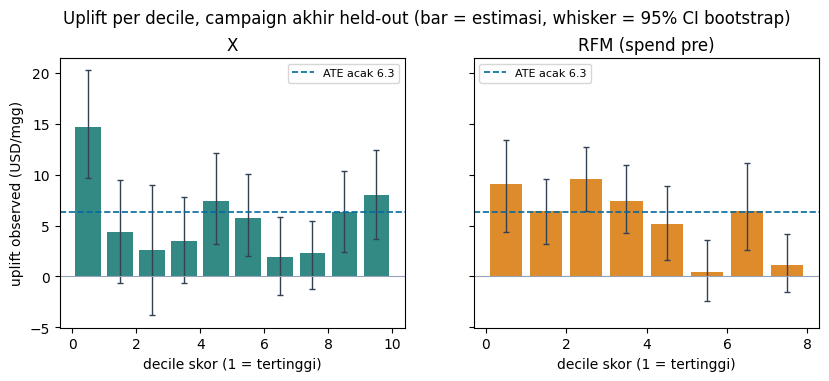

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.5), sharey=True)
for ax, name, color in [(axes[0], "X", "#0f766e"), (axes[1], "RFM (spend pre)", "#d97706")]:
    dec = ev["deciles"][name]
    mid = (dec["decile"] - 0.5).to_numpy()
    err = np.vstack([dec["uplift"] - dec["ci_low"], dec["ci_high"] - dec["uplift"]])
    ax.bar(mid, dec["uplift"], width=0.8, color=color, alpha=0.85)
    ax.errorbar(mid, dec["uplift"], yerr=err, fmt="none", ecolor="#334155", lw=1, capsize=2)
    ax.axhline(base["ate"], color="#0369a1", lw=1.2, ls="--", label=f"ATE acak {base['ate']:.1f}")
    ax.axhline(0, color="#94a3b8", lw=0.8)
    ax.set_xlabel("decile skor (1 = tertinggi)")
    ax.set_title(name)
    ax.legend(fontsize=8)
axes[0].set_ylabel("uplift observed (USD/mgg)")
fig.suptitle("Uplift per decile, campaign akhir held-out (bar = estimasi, whisker = 95% CI bootstrap)", y=1.02)
plt.show()

**Decile atas X-learner adalah temuan utama tahap ini; urutan di bawahnya tidak boleh dibaca halus.** Decile 1 X-learner menunjukkan uplift **+$14,7/minggu (95% CI 9,7–20,2)** — sekitar 2,3× efek rata-rata acak $6,3 — dan pada metrik anggaran terbatas (gain saat menarget 20% populasi) X menghasilkan **+$11,3 per member per minggu**, melampaui RFM naif (+$8,1) dan jauh di atas acak. Tapi kejujurannya dua: decile tengah tidak monoton (beberapa CI memuat nol — heterogenitas nyata terkonsentrasi di decile atas), dan decile 10 justru tinggi (+$8,0) — sebagian keunggulan AUUC X datang dari menaruh efek besar di ujung bawah, bukan dari urutan yang rapi.

RFM naif tetap lawan serius: decile 1–5-nya stabil positif dan seluruh keunggulannya berasal dari member belanja besar — yang memang sudah paling sering ditarget retailer. Yang menarik, skor X berkorelasi **negatif** (−0,31) dengan RFM: X menemukan responsif justru di member belanja menengah-kecil di margin penargetan — populasi yang oleh RFM ditempatkan di decile bawah. Dua skor ini komplementer, bukan duplikat. Decile 9–10 RFM bahkan tak bisa diklaim: jumlah treated-nya di bawah 30 (12–20 member) dan sel dibiarkan kosong, bukan dipaksakan.

In [8]:
# subset campaign test yang lolos gate (identifikasi bersih) — angka pembanding
mask = test["reliability_flag"].str.startswith("layak").to_numpy()
ev_layak = evaluate_scores(test[mask], {k: v[mask] for k, v in scores.items()}, n_boot=1000)
b2 = ev_layak["baseline_random"]
print(f"test lolos gate: n={b2['n']:,} | ATE acak {b2['ate']:+.2f} [{b2['ci_low']:+.2f}; {b2['ci_high']:+.2f}]")
for name, s in ev_layak["by_model"].items():
    print(f"{name:18s} skill {s['skill']:8.0f}  per member {s['skill_per_client']:+.3f}")

test lolos gate: n=8,021 | ATE acak +8.26 [+5.87; +10.57]
T                  skill     -899  per member -0.112
X                  skill     4792  per member +0.597
RFM (spend pre)    skill     2211  per member +0.276


## Placebo: treatment palsu di periode pra-campaign

Validasi terakhir: label treated dipermutasikan acak di dalam tiap campaign, outcome diganti perubahan belanja di jendela pra-campaign (yang tak mungkin tersentuh treatment), lalu seluruh pipeline — fit model, skor, decile, CI — dijalankan ulang dari nol. Pipeline yang benar harus mengembalikan efek yang tak terbedakan dari nol.

In [9]:
t0 = time.time()
plc = placebo_permutation(train, test, n_boot=1000)
print(f"placebo {time.time()-t0:.0f}s")
pb = plc["baseline_random"]
print(f"ATE placebo (treatment dipermutasi): {pb['ate']:+.2f} USD/mgg (95% CI {pb['ci_low']:+.2f} s.d. {pb['ci_high']:+.2f}) — CI memuat 0: {pb['ci_low'] <= 0 <= pb['ci_high']}")
print(f"skill AUUC pipeline pada data placebo: {plc['summary']['skill']:+.0f} (≈0 di bawah sampling noise)")
top = plc["deciles"].iloc[0]
print(f"decile 1 placebo: {top['uplift']:+.2f} [{top['ci_low']:+.2f}; {top['ci_high']:+.2f}] — CI memuat 0: {top['ci_low'] <= 0 <= top['ci_high']}")

placebo 4s
ATE placebo (treatment dipermutasi): +1.71 USD/mgg (95% CI -0.39 s.d. +3.61) — CI memuat 0: True
skill AUUC pipeline pada data placebo: -516 (≈0 di bawah sampling noise)
decile 1 placebo: +6.71 [-2.15; +15.61] — CI memuat 0: True


Placebo lolos: ATE pada data palsu +$1,7/minggu dengan CI yang memuat nol (−0,4 s.d. 3,6), decile atas CI-nya juga memuat nol, dan skill pipeline justru sedikit negatif — tidak ada efek phantom yang diproduksi mesin evaluasi.

## Batasan dan apa yang dibawa ke simulasi ROI

- **Semua tetap observational** — di bawah asumsi unconfoundedness. Propensity + overlap weighting + placebo mengurangi bias seleksi win-back, tidak menghapusnya; decile tengah yang tidak monoton adalah pengingat bahwa heterogenitas di luar decile atas belum terurut rapi oleh model.
- **Margin antara model dan baseline bergantung spek**: pada validasi silang sisi train (OOF, dikelompokkan per household) keunggulan X-learner atas acak tipis (+$0,04/member); keunggulan besar (+$0,63) muncul di campaign akhir yang efek rata-ratanya juga lebih tinggi. Angka decile atas dibaca sebagai indikatif dengan CI, bukan presisi — persis alasan setiap sel dilaporkan dengan n dan CI.
- T-learner tidak konsisten (skill positif di test campuran, negatif di subset lolos gate) — dicatat apa adanya; hanya X-learner yang dipakai sebagai kandidat skor utama, dengan RFM sebagai pembanding wajib.
- Artefak tahap ini: skor per (member, campaign akhir) beserta propensity, bobot, flag reliabilitas, dan segmen — bahan langsung skenario targeting simulasi ROI berikutnya.

In [10]:
scores_out, results_out = save_stage2_outputs(test, scores, ev)
print(f"uplift_scores.parquet: {scores_out.shape[0]:,} baris × {scores_out.shape[1]} kolom (grain household × campaign test)")
print(f"kolom skor: {[c for c in scores_out.columns if c.startswith('score_')]}")
print(f"uplift_eval_results.parquet: {results_out.shape[0]} baris decile ({results_out['model'].nunique()} skor × 10 decile)")

uplift_scores.parquet: 14,090 baris × 14 kolom (grain household × campaign test)
kolom skor: ['score_t', 'score_x', 'score_rfm']
uplift_eval_results.parquet: 30 baris decile (3 skor × 10 decile)
